# Laser fundamentals: gain, threshold, output coupling and modes

A laser is an optical amplifier inside a resonator. The amplifier is a
medium with more atoms in an upper than in a lower level, so that
stimulated emission beats absorption; the resonator returns part of the
light for another pass and lets the rest out. Everything else follows from
a few balances: the gain saturates until it equals the loss (threshold and
output power), only frequencies that fit the resonator survive
(longitudinal and transverse modes), and gain and photon number push each
other around before they settle (relaxation oscillations).

Notebook 08 (ABCD matrices) treats the passive resonator, its stability
and its Gaussian modes; this notebook adds the gain, with the `lasers`
module:

1. Einstein coefficients, line shapes and cross sections,
2. three and four level lasers,
3. gain saturation and amplifiers,
4. threshold, slope efficiency and the optimum output coupler of a diode
   pumped Nd:YVO₄ laser,
5. longitudinal and transverse modes, the cavity linewidth and the
   Schawlow–Townes limit,
6. relaxation oscillations from the rate equations.

Notebook 143 (Q-switching and mode-locking) makes pulses from the same
equations, notebook 144 (laser diodes) does it for semiconductors.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import lasers as L
from pyoptics import abcd
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. Einstein coefficients, line shapes and cross sections

Einstein's three processes connect two levels: spontaneous emission at the
rate $A_{21}$, and absorption and stimulated emission at rates
proportional to the spectral energy density of the light, with
$g_1B_{12} = g_2B_{21}$ and

$$\frac{A_{21}}{B_{21}} = \frac{8\pi h n^3}{\lambda^3}.$$

A real transition is not infinitely sharp. Each atom emits with a
Lorentzian line shape of width $1/(2\pi T_2)$ (homogeneous broadening:
lifetime, collisions, phonons in a crystal); atoms that see different
surroundings or move at different speeds add up to a Gaussian
(inhomogeneous broadening: Doppler in a gas, site to site variations in
a glass). With the normalized line shape $g(\nu)$ the rates turn into a
**cross section**, the area per atom that removes or adds photons,

$$\sigma(\nu) = \frac{\lambda^2}{8\pi n^2\tau_{rad}}\,g(\nu),$$

and an inversion density $\Delta N = N_2 - (g_2/g_1)N_1$ gives the gain
coefficient $g = \sigma\Delta N$. The cross section is large for a long
wavelength, a short radiative lifetime and a narrow line. The table
checks the formula against measured values; $\tau_{rad}$ is the lifetime
of the one line that lases (for Nd:YAG about 9 % of the decays of the
upper level end in the Stark component at 1064 nm).

transition            line width      shape    tau_rad  sigma (cm²)       listed
HeNe 632.8 nm             1.5 GHz   gaussian   0.294 µs     3.39e-13      3.0e-13
Nd:YAG 1064 nm            120 GHz lorentzian 2.6e+03 µs     2.78e-19      2.8e-19
Nd:YVO₄ 1064 nm           260 GHz lorentzian     430 µs     5.45e-19      1.6e-18
Ti:sapphire 800 nm      1e+05 GHz lorentzian     3.2 µs     1.64e-19      3.0e-19

Nd:YAG 1064 nm line: A21 = 385 1/s, B21 = 4.62e+15 m³/(J s²)


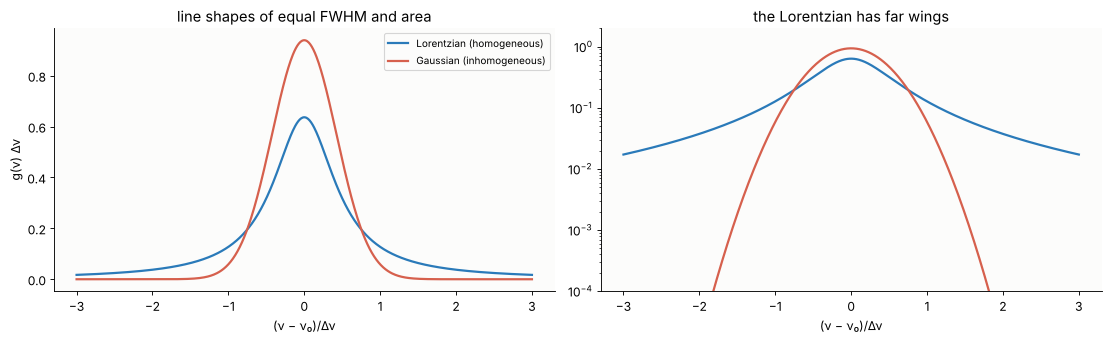

In [2]:
cases = [  # name, wavelength, line width, shape, radiative lifetime of the laser line, n
    ("HeNe 632.8 nm", 632.8E-9, 1.5E9, "gaussian", 1/3.4E6, 1.0),
    ("Nd:YAG 1064 nm", 1064.2E-9, 120E9, "lorentzian", 2.6E-3, 1.82),
    ("Nd:YVO₄ 1064 nm", 1064.3E-9, 260E9, "lorentzian", 0.43E-3, 2.17),
    ("Ti:sapphire 800 nm", 800E-9, 100E12, "lorentzian", 3.2E-6, 1.76),
]
listed = {"HeNe 632.8 nm": 3E-17, "Nd:YAG 1064 nm": 2.8E-23, "Nd:YVO₄ 1064 nm": 15.6E-23,
          "Ti:sapphire 800 nm": 3.0E-23}
print("{:20s} {:>11s} {:>10s} {:>10s} {:>12s} {:>12s}".format(
    "transition", "line width", "shape", "tau_rad", "sigma (cm²)", "listed"))
for name, wl, dnu, shape, tau_r, n in cases:
    s = L.peak_cross_section(wl, tau_r, dnu, shape, n)
    print("{:20s} {:>8.3g} GHz {:>10s} {:>7.3g} µs {:>12.2e} {:>12.1e}".format(
        name, dnu/1E9, shape, tau_r*1E6, s*1E4, listed[name]*1E4))

e = L.einstein_coefficients(1/2.6E-3, 1064.2E-9, n=1.82)
print("\nNd:YAG 1064 nm line: A21 = {:.0f} 1/s, B21 = {:.3g} m³/(J s²)".format(e["A21"], e["B21"]))

nu = np.linspace(-3, 3, 601)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
ax.plot(nu, L.lorentzian(nu, 0, 1), color=BLUE, lw=2, label="Lorentzian (homogeneous)")
ax.plot(nu, L.gaussian_line(nu, 0, 1), color=RED, lw=2, label="Gaussian (inhomogeneous)")
ax.set_xlabel("(ν − ν₀)/Δν"); ax.set_ylabel("g(ν) Δν")
ax.set_title("line shapes of equal FWHM and area")
ax.legend(fontsize=9)
ax = axes[1]
ax.semilogy(nu, L.lorentzian(nu, 0, 1), color=BLUE, lw=2)
ax.semilogy(nu, L.gaussian_line(nu, 0, 1), color=RED, lw=2)
ax.set_ylim(1E-4, 2); ax.set_xlabel("(ν − ν₀)/Δν")
ax.set_title("the Lorentzian has far wings")
plt.tight_layout()
plt.show()

The formula reproduces the measured cross sections of the HeNe and the
neodymium lasers within 15 %; for Ti:sapphire, whose 100 THz wide band is
far from Lorentzian, it is within a factor of two. The cross sections span
six decades: 3·10⁻¹³ cm² for the narrow Doppler line of a gas,
10⁻¹⁹ cm² for rare earth ions in crystals, whose 4f electrons are
shielded but whose transitions are weak. A gas laser therefore has high
gain per atom but few atoms, a crystal many atoms (10²⁰ cm⁻³) that store
energy for hundreds of microseconds.

## 2. Three and four level lasers

Two levels alone cannot be inverted by optical pumping: the pump
stimulates emission as fast as absorption, and at best the populations
equalize. A third level helps. In a **three level** laser (ruby, and
Yb and Er at room temperature in part) the pump lifts atoms from the
ground state into a band that decays fast into the upper laser level, and
the laser ends on the ground state. In a **four level** laser (Nd, Ti,
most gas lasers) it ends on a level above the ground state that empties
within nanoseconds. The steady state rate equations with the pump rate
$W_p$ and the lifetime $\tau$ give

$$\frac{\Delta N}{N} = \frac{W_p\tau - 1}{W_p\tau + 1}\ \text{(three level)},\qquad
  \frac{\Delta N}{N} = \frac{W_p\tau}{W_p\tau + 1}\ \text{(four level)}.$$

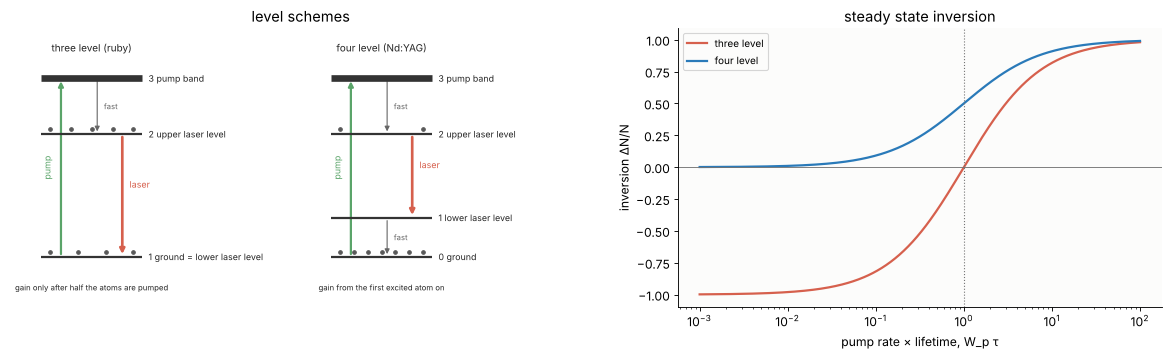

gain 0.00/cm: ruby needs 50.0 % of its Cr ions up,    972 W/cm³ of pump; Nd:YAG 0.000 % of its Nd ions,    0 W/cm³
gain 0.01/cm: ruby needs 51.3 % of its Cr ions up,    996 W/cm³ of pump; Nd:YAG 0.026 % of its Nd ions,   38 W/cm³
gain 0.10/cm: ruby needs 62.5 % of its Cr ions up,   1215 W/cm³ of pump; Nd:YAG 0.259 % of its Nd ions,  382 W/cm³


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
sketch.laser_layout(axes[0], "levels", title="level schemes")
Wt = np.logspace(-3, 2, 400)
ax = axes[1]
ax.semilogx(Wt, L.three_level_inversion(Wt, 1.0), color=RED, lw=2, label="three level")
ax.semilogx(Wt, L.four_level_inversion(Wt, 1.0), color=BLUE, lw=2, label="four level")
ax.axhline(0, color=GREY, lw=0.8)
ax.axvline(1, color=GREY, ls=":", lw=1)
ax.set_xlabel("pump rate × lifetime, W_p τ"); ax.set_ylabel("inversion ΔN/N")
ax.set_title("steady state inversion")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

# absorbed pump power per volume that keeps a given gain: every atom in the
# upper level decays in tau and must be pumped again
ruby, yag = L.GAIN_MEDIA["Ruby"], L.GAIN_MEDIA["Nd:YAG"]
for g in (0.0, 0.01E2, 0.1E2):                     # gain coefficient (1/m)
    dN_r = g/ruby["sigma"]
    N2_r = (ruby["N"] + dN_r)/2                    # three level: N2 - N1 = dN, N1 + N2 = N
    p_r = N2_r*L.photon_energy(ruby["pump"])/ruby["tau"]
    dN_y = g/yag["sigma"]                          # four level: N2 = dN
    p_y = dN_y*L.photon_energy(yag["pump"])/yag["tau"]
    print("gain {:4.2f}/cm: ruby needs {:4.1f} % of its Cr ions up, {:6.0f} W/cm³ of pump; "
          "Nd:YAG {:5.3f} % of its Nd ions, {:4.0f} W/cm³".format(
              g/100, N2_r/ruby["N"]*100, p_r*1E-6, dN_y/yag["N"]*100, p_y*1E-6))

A three level medium is absorbing until more than half of its atoms are
pumped. For ruby that alone takes almost 1 kW of absorbed pump per cm³,
which Maiman got from a flash lamp in 1960, for a millisecond; any gain
comes on top. A four level medium has gain from the first pumped atom
on: a gain of 0.01 cm⁻¹, enough for a continuous laser with good mirrors,
needs 0.03 % of the Nd ions in Nd:YAG and 38 W/cm³, 26 times less than
ruby. That is why almost all continuous lasers are four level lasers, and why
the three level Yb:YAG and Er lasers need bright diode pumps (and work
as "quasi three level" lasers whose lower level is only partly
populated at room temperature).

## 3. Gain saturation and amplifiers

Strong light depletes the inversion it feeds on. For a four level medium
the stimulated rate $\sigma I/h\nu$ competes with the decay $1/\tau$, and
the gain falls to half at the **saturation intensity**
$I_{sat} = h\nu/(\sigma\tau)$. A homogeneously broadened line saturates
as a whole, $g = g_0/(1 + I/I_{sat})$; an inhomogeneous line only near the
frequency of the light, and the remaining atoms of other frequencies keep
their gain, $g = g_0/\sqrt{1 + I/I_{sat}}$ (spectral hole burning).

In an amplifier the intensity grows along $z$ as
$dI/dz = g_0I/(1 + I/I_{sat})$: exponentially while $I \ll I_{sat}$,
then only linearly, adding at most $g_0I_{sat}$ per unit length.
`L.amplifier_gain()` solves the integrated equation. A pulse much
shorter than $\tau$ meets the stored energy instead, and its fluence grows
by the Frantz–Nodvik law up to the stored $E_{sat}\ln G_0$ with the
saturation fluence $E_{sat} = h\nu/\sigma$.

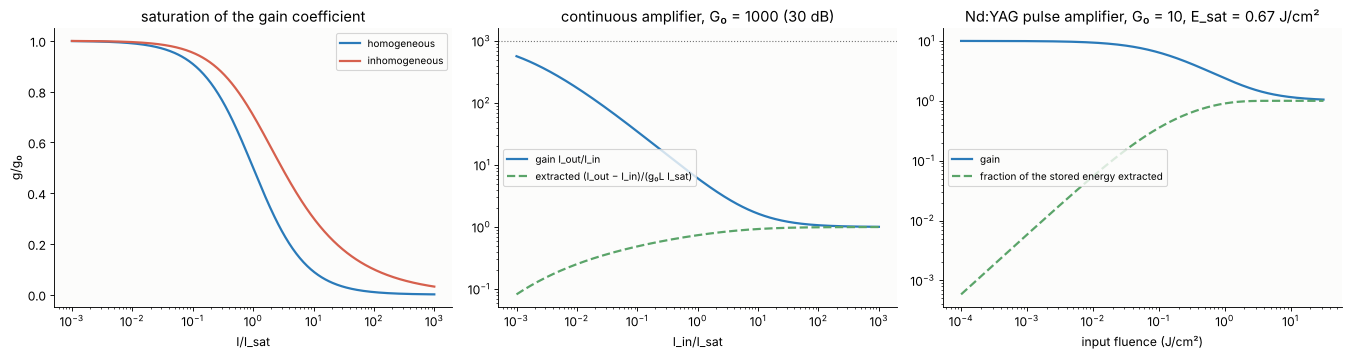

I_in =  0.00 I_sat: gain   567.5 (27.5 dB), extracts  8.2 % of g0 L I_sat
I_in =  0.01 I_sat: gain   175.2 (22.4 dB), extracts 25.2 % of g0 L I_sat
I_in =  0.10 I_sat: gain    34.6 (15.4 dB), extracts 48.7 % of g0 L I_sat
I_in =  1.00 I_sat: gain     6.1 ( 7.9 dB), extracts 73.8 % of g0 L I_sat
I_in = 10.00 I_sat: gain     1.6 ( 2.2 dB), extracts 92.8 % of g0 L I_sat
pulse of 0.01 J/cm²: out 0.094 J/cm², gain 9.38, 5 % of the stored 1.54 J/cm²
pulse of 0.10 J/cm²: out 0.642 J/cm², gain 6.42, 35 % of the stored 1.54 J/cm²
pulse of 1.00 J/cm²: out 2.386 J/cm², gain 2.39, 90 % of the stored 1.54 J/cm²


In [4]:
x = np.logspace(-3, 3, 400)
G0 = 1000.0
G = L.amplifier_gain(G0, x, 1.0)
yag_E = L.photon_energy(1064E-9)/yag["sigma"]                  # J/m²
E_in = np.logspace(-4, 1.5, 300)*1E4                           # J/m²
G_p = 10.0
E_out = L.frantz_nodvik(E_in, yag_E, G_p)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
ax.semilogx(x, L.saturated_gain(1, x, 1), color=BLUE, lw=2, label="homogeneous")
ax.semilogx(x, L.saturated_gain(1, x, 1, "inhomogeneous"), color=RED, lw=2, label="inhomogeneous")
ax.set_xlabel("I/I_sat"); ax.set_ylabel("g/g₀"); ax.legend(fontsize=9)
ax.set_title("saturation of the gain coefficient")
ax = axes[1]
ax.loglog(x, G, color=BLUE, lw=2, label="gain I_out/I_in")
ax.loglog(x, (G - 1)*x/np.log(G0), color=GREEN, lw=2, ls="--",
          label="extracted (I_out − I_in)/(g₀L I_sat)")
ax.axhline(G0, color=GREY, ls=":", lw=1)
ax.set_xlabel("I_in/I_sat"); ax.set_title(f"continuous amplifier, G₀ = {G0:.0f} (30 dB)")
ax.legend(fontsize=9, loc="center left")
ax = axes[2]
ax.loglog(E_in*1E-4, E_out/E_in, color=BLUE, lw=2, label="gain")
ax.loglog(E_in*1E-4, (E_out - E_in)/(yag_E*np.log(G_p)), color=GREEN, lw=2, ls="--",
          label="fraction of the stored energy extracted")
ax.set_xlabel("input fluence (J/cm²)")
ax.set_title(f"Nd:YAG pulse amplifier, G₀ = {G_p:.0f}, E_sat = {yag_E*1E-4:.2f} J/cm²")
ax.legend(fontsize=9, loc="center left")
plt.tight_layout()
plt.show()

for xi in (0.001, 0.01, 0.1, 1.0, 10.0):
    g = float(L.amplifier_gain(G0, xi, 1.0))
    print("I_in = {:5.2f} I_sat: gain {:7.1f} ({:4.1f} dB), extracts {:4.1f} % of g0 L I_sat".format(
        xi, g, 10*np.log10(g), (g - 1)*xi/np.log(G0)*100))
for Ei in (0.01, 0.1, 1.0):
    Eo = float(L.frantz_nodvik(Ei*1E4, yag_E, G_p))*1E-4
    print("pulse of {:4.2f} J/cm²: out {:.3f} J/cm², gain {:.2f}, {:.0f} % of the stored {:.2f} J/cm²".format(
        Ei, Eo, Eo/Ei, (Eo - Ei)/(yag_E*1E-4*np.log(G_p))*100, yag_E*1E-4*np.log(G_p)))

The continuous amplifier keeps its 30 dB of small signal gain only for
inputs below a ten thousandth of $I_{sat}$; at 0.01 $I_{sat}$ it is down
to 22 dB and at $I_{sat}$ to 8 dB, but it then delivers three quarters of
what the medium can give, $g_0LI_{sat}$. A pulse amplifier behaves alike
in fluence: Nd:YAG at a gain of 10 stores 1.5 J/cm², a pulse of
0.01 J/cm² takes out 5 % of it, one of 1 J/cm², above the saturation
fluence of 0.67 J/cm² and near the damage threshold of coatings, 90 %. Amplifier chains are therefore designed
around $I_{sat}$ and $E_{sat}$: high gain stages for weak signals,
saturated power stages at the end.

## 4. Threshold, slope efficiency and output coupling

In a resonator the light passes the gain medium again and again. It
grows from spontaneous emission as long as the round trip gain beats the
round trip loss, and saturates the gain down to it. **Threshold** is the
point where the small signal gain just equals the loss,

$$2g_{th}l = \delta = -\ln R_1R_2 + \delta_i = T + \delta_i\ (\text{small }T),$$

with the output coupler transmission $T$ and the internal loss
$\delta_i$ per round trip. Above threshold the gain stays clamped at
$g_{th}$, the inversion stops growing, and every additional pump photon
above threshold turns into a laser photon, either coupled out or lost
inside. The output power is linear in the pump power with the **slope
efficiency**

$$\eta_s = \eta_p\,\eta_{mode}\,\frac{\lambda_p}{\lambda_l}\,\frac{T}{T + \delta_i},$$

the product of the absorbed pump fraction, the overlap of pump and laser
mode, the quantum defect and the output coupling efficiency. The example
is a diode pumped Nd:YVO₄ laser: a 3 mm crystal with its pumped face
coated as the plane end mirror, a concave output coupler
($R$ = 100 mm) 50 mm away, 808 nm pump focused to the size of the
laser mode, 1 % internal loss, 90 % of the pump absorbed. The resonator
is treated as in notebook 08 (ABCD matrices): its eigenmode sets the
mode area.

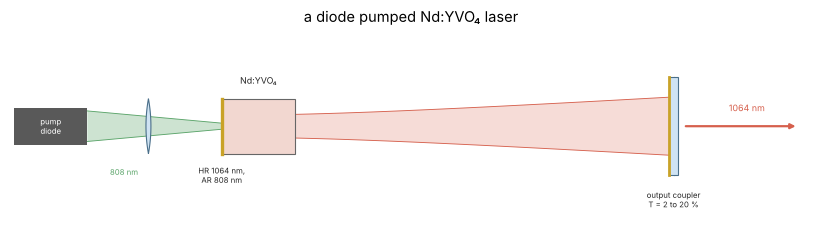

mode radius on the crystal 130 µm, I_sat = 1.22 kW/cm², P_sat = I_sat A = 650 mW


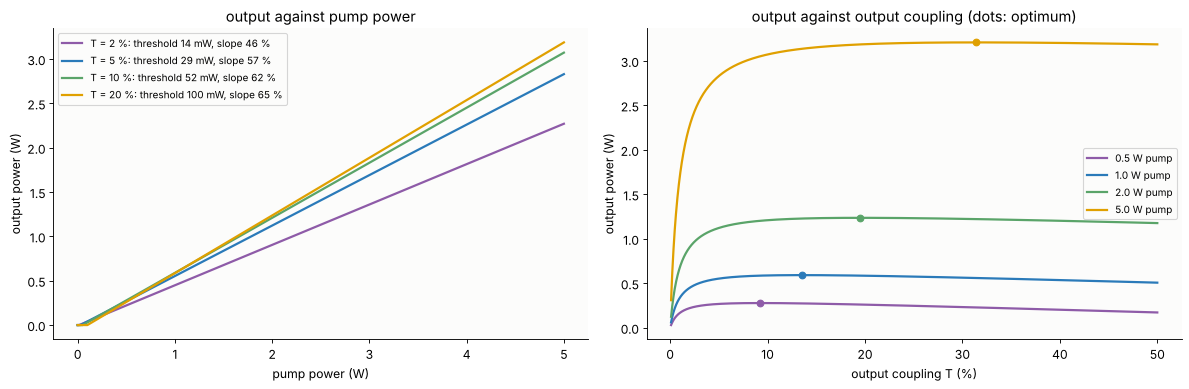

pump 0.5 W: 2 g0 l =  1.05, optimum T =  9.3 %, output 0.28 W (56 % optical efficiency)
pump 1.0 W: 2 g0 l =  2.10, optimum T = 13.5 %, output 0.59 W (59 % optical efficiency)
pump 2.0 W: 2 g0 l =  4.21, optimum T = 19.5 %, output 1.24 W (62 % optical efficiency)
pump 5.0 W: 2 g0 l = 10.52, optimum T = 31.4 %, output 3.21 W (64 % optical efficiency)


In [5]:
fig, ax = plt.subplots(figsize=(13, 3.6))
sketch.laser_layout(ax, "end_pumped", title="a diode pumped Nd:YVO₄ laser")
plt.show()

vo = L.GAIN_MEDIA["Nd:YVO4"]
wl, wl_p, sigma, tau = vo["wavelength"], vo["pump"], vo["sigma"], vo["tau"]
L_cav, R_oc, l_xtal = 0.05, 0.10, 3E-3
M_rt = abcd.compose(abcd.free_space(L_cav), abcd.mirror(R_oc), abcd.free_space(L_cav),
                    abcd.mirror(np.inf))
q_mode = abcd.eigenmode(M_rt)
w_l = abcd.beam_radius(q_mode, wl)
w_p = w_l
A_eff = np.pi*(w_l**2 + w_p**2)/2
delta_i, eta_p = 0.01, 0.9
I_sat = L.saturation_intensity(wl, sigma, tau)
P_sat = I_sat*A_eff
print("mode radius on the crystal {:.0f} µm, I_sat = {:.2f} kW/cm², P_sat = I_sat A = {:.0f} mW".format(
    w_l*1E6, I_sat*1E-7, P_sat*1E3))


def g0l2_of(P_pump):
    """round trip small signal gain 2 g0 l for the pump power (W)"""
    return 2*sigma*tau*eta_p*P_pump/(L.photon_energy(wl_p)*A_eff)


P_pump = np.linspace(0, 5, 501)
Ts = (0.02, 0.05, 0.10, 0.20)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
for T, c in zip(Ts, (PURPLE, BLUE, GREEN, ORANGE)):
    P_out = L.output_power(T, g0l2_of(P_pump), delta_i, P_sat)
    P_th = L.threshold_pump_power(T + delta_i, sigma, tau, wl_p, A_eff, eta_p)
    eta = L.slope_efficiency(T, delta_i, wl_p, wl, eta_p)
    ax.plot(P_pump, P_out, color=c, lw=2,
            label=f"T = {T*100:.0f} %: threshold {P_th*1E3:.0f} mW, slope {eta*100:.0f} %")
ax.set_xlabel("pump power (W)"); ax.set_ylabel("output power (W)")
ax.set_title("output against pump power")
ax.legend(fontsize=9)
ax = axes[1]
T = np.linspace(0.001, 0.5, 2000)
for Pp, c in zip((0.5, 1.0, 2.0, 5.0), (PURPLE, BLUE, GREEN, ORANGE)):
    ax.plot(T*100, L.output_power(T, g0l2_of(Pp), delta_i, P_sat), color=c, lw=2, label=f"{Pp:.1f} W pump")
    T_opt, P_max = L.optimum_output_coupling(g0l2_of(Pp), delta_i, P_sat)
    ax.plot(T_opt*100, P_max, "o", color=c)
ax.set_xlabel("output coupling T (%)"); ax.set_ylabel("output power (W)")
ax.set_title("output against output coupling (dots: optimum)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

for Pp in (0.5, 1.0, 2.0, 5.0):
    T_opt, P_max = L.optimum_output_coupling(g0l2_of(Pp), delta_i, P_sat)
    print("pump {:.1f} W: 2 g0 l = {:5.2f}, optimum T = {:4.1f} %, output {:.2f} W ({:.0f} % optical efficiency)".format(
        Pp, g0l2_of(Pp), T_opt*100, P_max, P_max/Pp*100))

The Nd:YVO₄ laser starts at 14 to 100 mW of pump, depending on the
output coupler, and then converts pump into output at 46 to 65 %; the
ceiling of these slopes is the quantum defect (808/1064 = 76 %) times
the absorbed fraction. A weak output coupler gives a low threshold but
wastes a larger share of the circulating power in the internal loss; a
strong one keeps the internal loss small in comparison but needs more
gain to start. The optimum, $T_{opt} = \sqrt{2g_0l\,\delta_i} - \delta_i$,
grows with the pump: 9 % at 0.5 W, 31 % at 5 W, and the curve is flat
around it, so the coupler is chosen for the pump power at which the laser
will run.

These formulas assume small losses and gains per pass, so that the
intensity is nearly the same everywhere in the resonator. **Rigrod's**
exact solution of the two counter-running beams in a saturated
homogeneous medium covers any gain and any mirror. The comparison is for
a high gain medium ($g_0l$ = 1.5, a gain of 4.5 per pass, as in a CO₂ or
a fibre laser) behind a 100 % mirror.

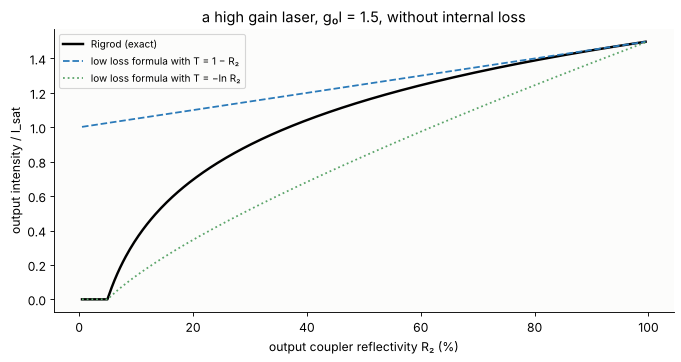

R2 = 30 %: Rigrod 0.898 I_sat, low loss formula with T = 1 − R2 1.150, with T = −ln R2 0.522
R2 = 50 %: Rigrod 1.153 I_sat, low loss formula with T = 1 − R2 1.250, with T = −ln R2 0.832
R2 = 70 %: Rigrod 1.322 I_sat, low loss formula with T = 1 − R2 1.350, with T = −ln R2 1.112
R2 = 90 %: Rigrod 1.447 I_sat, low loss formula with T = 1 − R2 1.450, with T = −ln R2 1.374


In [6]:
R2 = np.linspace(0.005, 0.995, 400)
g0l = 1.5
exact = L.rigrod_output(g0l, 1.0, 1.0, R2, 1.0)
approx = L.output_power(1 - R2, 2*g0l, 0.0, 2.0)/2   # P_sat = 2 I_sat: the two beams add
approx_log = L.output_power(-np.log(R2), 2*g0l, 0.0, 2.0)/2*(1 - R2)/(-np.log(R2))
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(R2*100, exact, color="k", lw=2.2, label="Rigrod (exact)")
ax.plot(R2*100, approx, color=BLUE, lw=1.6, ls="--", label="low loss formula with T = 1 − R₂")
ax.plot(R2*100, approx_log, color=GREEN, lw=1.6, ls=":", label="low loss formula with T = −ln R₂")
ax.set_xlabel("output coupler reflectivity R₂ (%)"); ax.set_ylabel("output intensity / I_sat")
ax.set_title("a high gain laser, g₀l = 1.5, without internal loss")
ax.legend(fontsize=9)
plt.show()
i = np.argmax(exact)
for r2 in (0.3, 0.5, 0.7, 0.9):
    print("R2 = {:2.0f} %: Rigrod {:.3f} I_sat, low loss formula with T = 1 − R2 {:.3f}, with T = −ln R2 {:.3f}".format(
        r2*100, float(L.rigrod_output(g0l, 1.0, 1.0, r2, 1.0)), float(L.output_power(1 - r2, 2*g0l, 0.0, 2.0))/2,
        float(L.output_power(-np.log(r2), 2*g0l, 0.0, 2.0))/2*(1 - r2)/(-np.log(r2))))

Without internal loss every photon ends up in the output, and the output
grows towards $g_0lI_{sat}$ as $R_2 \to 1$; internal loss is what creates
an optimum. What the comparison shows is how forgiving a high gain laser
is: the output falls by only 12 % at $R_2$ = 70 % and by 40 % at
$R_2$ = 30 %, and the laser runs down to $R_2 = e^{-2g_0l}$ = 5 %. The low
loss formula brackets Rigrod's result, too high with $T = 1 - R_2$ and too
low with $T = -\ln R_2$; the first is good to a few percent above
$R_2 \approx$ 70 %, the second only above 90 %. Lasers with a gain of 10 dB per pass, like fibre
lasers, therefore often use a bare cleaved fibre end (4 %) as output
coupler.

## 5. Longitudinal and transverse modes, linewidth

A mode of the resonator repeats itself after a round trip, including its
phase. For the Gaussian modes $\mathrm{TEM}_{mn}$ of notebook 08 (ABCD matrices)
the round trip phase is $2\pi$ times an integer $q$, which
includes the Gouy phase $\psi$ of the round trip:

$$\nu_{qmn} = \frac{c}{2L_{opt}}\left(q + (m + n + 1)\frac{\psi}{2\pi}\right).$$

The longitudinal modes are spaced by the free spectral range $c/2L_{opt}$,
and the transverse modes sit between them at fractions set by the Gouy
phase; in a confocal resonator ($\psi = \pi$) they fall on top of each
other or halfway. Which modes lase depends on the gain line: all modes
with a round trip gain above the loss can.

optical length 53.5 mm, FSR 2.80 GHz, round trip Gouy phase 90.0°
93 modes within the FWHM of the gain line
1.1 times above threshold: 30 longitudinal modes with gain above the loss
1.5 times above threshold: 66 longitudinal modes with gain above the loss
3.0 times above threshold: 131 longitudinal modes with gain above the loss


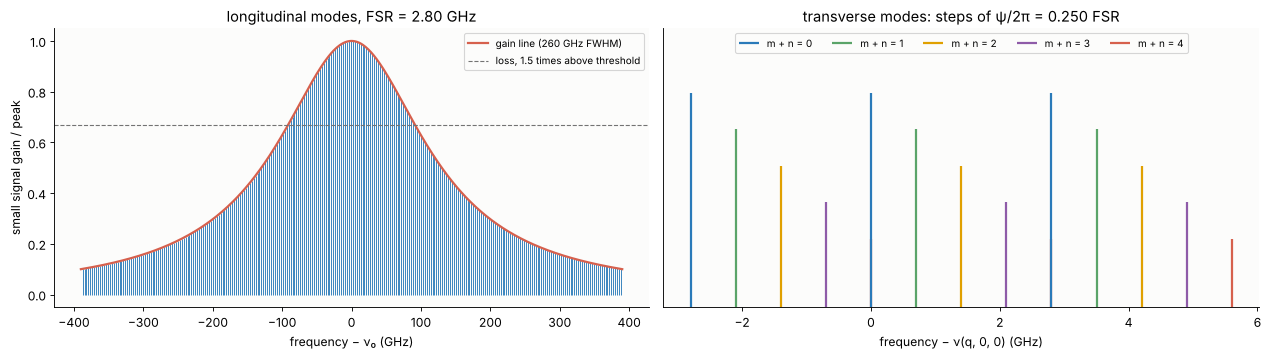

In [7]:
n_x = vo["n"]
L_opt = (L_cav - l_xtal) + n_x*l_xtal
fsr = L.free_spectral_range(L_opt)
psi = abcd.round_trip_gouy_phase(M_rt)
nu0 = L.C0/wl
dnu_g = vo["dnu"]
nu_modes, q = L.mode_frequencies(L_opt, nu0 - 1.5*dnu_g, nu0 + 1.5*dnu_g)
gain_line = L.lorentzian(nu_modes, nu0, dnu_g)/L.lorentzian(nu0, nu0, dnu_g)
print("optical length {:.1f} mm, FSR {:.2f} GHz, round trip Gouy phase {:.1f}°".format(
    L_opt*1E3, fsr/1E9, np.degrees(psi)))
print("{:.0f} modes within the FWHM of the gain line".format(dnu_g/fsr))
for r in (1.1, 1.5, 3.0):
    # modes whose small signal gain exceeds the loss r times above threshold
    n_above = np.sum(r*gain_line > 1)
    print("{:.1f} times above threshold: {} longitudinal modes with gain above the loss".format(r, n_above))

tr = L.transverse_mode_frequencies(M_rt, 2*L_opt, q[len(q)//2 - 1:len(q)//2 + 2], max_order=4)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
ax = axes[0]
ax.vlines((nu_modes - nu0)/1E9, 0, gain_line, color=BLUE, lw=0.8)
nn = np.linspace(nu0 - 1.5*dnu_g, nu0 + 1.5*dnu_g, 600)
ax.plot((nn - nu0)/1E9, L.lorentzian(nn, nu0, dnu_g)/L.lorentzian(nu0, nu0, dnu_g), color=RED, lw=2,
        label="gain line (260 GHz FWHM)")
ax.axhline(1/1.5, color=GREY, ls="--", lw=1, label="loss, 1.5 times above threshold")
ax.set_xlabel("frequency − ν₀ (GHz)"); ax.set_ylabel("small signal gain / peak")
ax.set_title(f"longitudinal modes, FSR = {fsr/1E9:.2f} GHz")
ax.legend(fontsize=9, loc="upper right")
ax = axes[1]
colors = [BLUE, GREEN, ORANGE, PURPLE, RED]
for k, row in enumerate(tr):
    for order, f in enumerate(row):
        ax.vlines((f - tr[1, 0])/1E9, 0, 1 - 0.17*order, color=colors[order], lw=2,
                  label=f"m + n = {order}" if k == 0 else None)
ax.set_xlabel("frequency − ν(q, 0, 0) (GHz)"); ax.set_yticks([])
ax.set_title(f"transverse modes: steps of ψ/2π = {psi/(2*np.pi):.3f} FSR")
ax.legend(fontsize=9, ncol=5, loc="upper center")
ax.set_ylim(0, 1.3)
plt.tight_layout()
plt.show()

The 5 cm cavity has a mode every 2.8 GHz, 93 of them within the 260 GHz
FWHM of the Nd:YVO₄ line; just above threshold dozens of them already
have gain above the loss, 130 at three times threshold. A homogeneous
line would in principle let only the mode at the peak survive, since the
clamped gain is the same for all modes; in a linear cavity, though, each
mode's standing wave leaves unsaturated gain at its nodes (spatial hole
burning), and the neighbours lase there. Single frequency operation needs
a ring cavity, an etalon, or a crystal so short that only one mode fits
under the line. With the output coupler at its own radius of curvature
the round trip Gouy phase is 90°, and each transverse order shifts the
mode by a quarter of the FSR, so that order 4 falls onto the next
longitudinal mode; an aperture or a pump spot smaller
than the higher modes keeps the laser on $\mathrm{TEM}_{00}$ (notebook 09,
mode analysis, decomposes a beam into such modes).

The **linewidth** of a single mode has two limits. A passive cavity mode
has the width $\Delta\nu_c = 1/(2\pi\tau_c)$ of its photon lifetime
$\tau_c$. Above threshold the gain compensates the loss, and only the
spontaneous emission that falls into the mode with a random phase
remains; the phase diffuses, and the **Schawlow–Townes** linewidth is

$$\Delta\nu_{ST} = \frac{\pi h\nu\,\Delta\nu_c^2\,n_{sp}}{P_{out}}\,(1 + \alpha^2),$$

with the population factor $n_{sp} = N_2/(N_2 - N_1) \ge 1$ and Henry's
linewidth enhancement factor $\alpha$, zero for atoms and ions but 3 to 6
in semiconductors (notebook 144, laser diodes).

In [8]:
lasers_lw = [  # name, wavelength, cavity length, n, R1 R2, internal loss per round trip, output power, n_sp, alpha
    ("HeNe, 30 cm, R = 99 %", 632.8E-9, 0.30, 1.0, 0.99, 0.0, 1E-3, 1.0, 0.0),
    ("Nd:YVO₄ above, T = 5 %", 1064.3E-9, L_opt, 1.0, 0.95, 0.01, 1.0, 1.0, 0.0),
    ("fibre laser, 2 m, T = 50 %", 1550E-9, 2.0, 1.45, 0.5, 0.0, 0.1, 1.2, 0.0),
    ("DFB laser diode, 250 µm", 1550E-9, 250E-6, 3.6, 0.32, 0.86, 5E-3, 2.0, 5.0),
]
print("{:30s} {:>12s} {:>12s} {:>14s}".format("laser", "tau_c", "cavity FWHM", "quantum limit"))
for name, wl_x, Lx, nx, R, d_i, P, nsp, alpha in lasers_lw:
    tau_c = 2*nx*Lx/(L.C0*(-np.log(R) + d_i))
    dnu_c = L.cavity_linewidth(tau_c)
    st = L.schawlow_townes(L.C0/wl_x, dnu_c, P*(1 - 0*R), nsp, alpha)
    print("{:30s} {:>9.3g} ns {:>8.3g} MHz {:>11.3g} Hz".format(name, tau_c*1E9, dnu_c/1E6, st))

laser                                 tau_c  cavity FWHM  quantum limit
HeNe, 30 cm, R = 99 %                199 ns    0.799 MHz     0.00063 Hz
Nd:YVO₄ above, T = 5 %              5.82 ns     27.3 MHz    0.000438 Hz
fibre laser, 2 m, T = 50 %          27.9 ns      5.7 MHz    0.000157 Hz
DFB laser diode, 250 µm            0.003 ns  5.3e+04 MHz    1.18e+07 Hz


The quantum limit is tiny for lasers with long, low loss cavities: below a
millihertz for a milliwatt HeNe laser, a watt from the Nd:YVO₄ laser or
a fibre laser. Real lasers are wider by many orders of magnitude,
because the cavity length itself fluctuates: 1 Hz of linewidth at
282 THz corresponds to length changes of 3·10⁻¹⁵ of the cavity, and
acoustic noise, thermal drifts of the mirrors and pump noise produce far
more. Narrow linewidth lasers therefore lock to stable reference cavities.
The semiconductor laser is different: its photon lifetime is only
picoseconds, its cavity linewidth 50 GHz, and its quantum limit (about
10 MHz at 5 mW, including the factor $1 + \alpha^2 \approx 26$) is what
one actually measures.

## 6. Relaxation oscillations

The time dependent balance of the inversion $N$ and the photon number
$\Phi$ in the mode is described by the **rate equations**. Normalized to
the threshold inversion and to the photon number at twice threshold they
read, with the pump $r$ relative to threshold,

$$\frac{dn}{dt} = \frac{r - n - np}{\tau},\qquad
  \frac{dp}{dt} = \frac{(n - 1)p + \beta n}{\tau_c}.$$

The steady state above threshold is $n = 1$ (clamped gain) and
$p = r - 1$ (output linear in the pump). When the pump is switched on, the
inversion first overshoots, the photons build up from the spontaneous
fraction $\beta$ into a spike that drives the inversion below threshold,
and the laser rings into its steady state at the **relaxation oscillation**
frequency

$$f_R = \frac{1}{2\pi}\sqrt{\frac{r - 1}{\tau\tau_c} - \left(\frac{r}{2\tau}\right)^2},
\qquad \text{damped at } \frac{r}{2\tau}.$$

r =  1.5: first spike    16 times the steady state at 114.2 µs; f_R = 149 kHz (simulated 149 kHz), decay time 130.7 µs


r =  3.0: first spike    18 times the steady state at  43.2 µs; f_R = 298 kHz (simulated 298 kHz), decay time 65.3 µs


r = 10.0: first spike    19 times the steady state at  12.0 µs; f_R = 632 kHz (simulated 632 kHz), decay time 19.6 µs


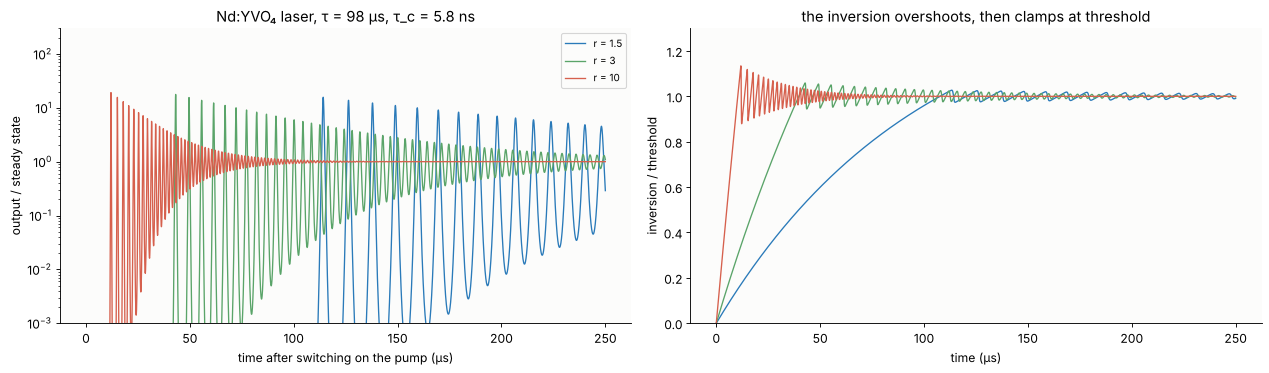

In [9]:
tau_c = L.photon_lifetime(L_opt, 1.0, 0.95, delta_i/(2*l_xtal), l_medium=l_xtal)
t = np.linspace(0, 250E-6, 250001)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for r, c in ((1.5, BLUE), (3.0, GREEN), (10.0, RED)):
    n, p = L.rate_equations(t, r, tau, tau_c, beta=1E-9)
    axes[0].plot(t*1E6, p/(r - 1), color=c, lw=1.2, label=f"r = {r:g}")
    axes[1].plot(t*1E6, n, color=c, lw=1.2)
    f_R, gam = L.relaxation_oscillation(r, tau, tau_c)
    # small signal ringing: well after the first spikes (four decay times)
    t_l = np.linspace(0, t[np.argmax(p)] + 6/gam, 400001)
    n_l, p_l = L.rate_equations(t_l, r, tau, tau_c, beta=1E-9)
    sel = t_l > t[np.argmax(p)] + 4/gam
    d = p_l[sel] - (r - 1)
    zc = np.nonzero(np.diff(np.sign(d)) != 0)[0]
    f_meas = (len(zc) - 1)/2/(t_l[sel][zc[-1]] - t_l[sel][zc[0]])
    print("r = {:4.1f}: first spike {:5.0f} times the steady state at {:5.1f} µs; f_R = {:.0f} kHz "
          "(simulated {:.0f} kHz), decay time {:.1f} µs".format(
              r, p.max()/(r - 1), t[np.argmax(p)]*1E6, f_R/1E3, f_meas/1E3, 1/gam*1E6))
axes[0].set_yscale("log"); axes[0].set_ylim(1E-3, 300)
axes[0].set_xlabel("time after switching on the pump (µs)"); axes[0].set_ylabel("output / steady state")
axes[0].set_title(f"Nd:YVO₄ laser, τ = {tau*1E6:.0f} µs, τ_c = {tau_c*1E9:.1f} ns")
axes[0].legend(fontsize=9)
axes[1].set_xlabel("time (µs)"); axes[1].set_ylabel("inversion / threshold")
axes[1].set_title("the inversion overshoots, then clamps at threshold")
axes[1].set_ylim(0, 1.3)
plt.tight_layout()
plt.show()

Once the ringing is small, its frequency agrees with the formula to
within a percent; the large first spikes ring slower, the oscillator is
nonlinear. Solid
state lasers ring at hundreds of kilohertz and settle within tens to
hundreds of microseconds, because their upper level lifetime is long;
the first spike reaches 16 to 19 times the steady output, a small
version of the Q switched pulse of notebook 143 (Q-switching and mode-locking).
Noise on the pump excites the same resonance, so the
intensity noise spectrum of a solid-state laser peaks at $f_R$. In a laser
diode both times are a thousand times shorter, nanoseconds and
picoseconds, and the relaxation oscillation moves to gigahertz, which
sets how fast it can be modulated (notebook 144, laser diodes).

## Summary

- **Cross section:** $\sigma = \lambda^2 g(\nu)/(8\pi n^2\tau_{rad})$,
  from 10⁻¹³ cm² for gas lines to 10⁻¹⁹ cm² for rare earth ions; the gain
  is $\sigma\Delta N$.
- **Level schemes:** three level media must invert half their atoms
  before they amplify (ruby: 1 kW/cm³ of pump), four level media
  amplify from the start (Nd:YAG: 38 W/cm³ for 0.01 cm⁻¹).
- **Saturation:** $I_{sat} = h\nu/(\sigma\tau)$ for continuous light,
  $E_{sat} = h\nu/\sigma$ for pulses; saturated amplifiers extract the
  stored energy.
- **Threshold and output:** the gain clamps at the loss; output rises
  linearly with the slope efficiency $\eta_p(\lambda_p/\lambda_l)T/(T + \delta_i)$;
  the optimum output coupler is $\sqrt{2g_0l\,\delta_i} - \delta_i$, and
  Rigrod's formula covers high gain.
- **Modes:** spaced by $c/2L$, transverse modes shifted by the Gouy
  phase; the quantum limited linewidth is below a millihertz for gas,
  solid-state and fibre lasers and megahertz for laser diodes.
- **Dynamics:** relaxation oscillations at
  $\sqrt{(r - 1)/(\tau\tau_c)}/2\pi$, hundreds of kHz for solid-state
  lasers.

In [10]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 47 s


## References

- A. E. Siegman, *Lasers*, University Science Books (1986), chapters 2
  to 7, 11, 12 and 25.
- O. Svelto, *Principles of Lasers*, 5th ed., Springer (2010).
- W. Koechner, *Solid-State Laser Engineering*, 6th ed., Springer (2006),
  chapters 1 to 3.
- B. E. A. Saleh and M. C. Teich, *Fundamentals of Photonics*, 3rd ed.,
  Wiley (2019), chapters 15 and 16.
- W. W. Rigrod, "Saturation effects in high-gain lasers", J. Appl. Phys.
  36, 2487–2490 (1965).
- L. M. Frantz and J. S. Nodvik, "Theory of pulse propagation in a laser
  amplifier", J. Appl. Phys. 34, 2346–2349 (1963).
- A. L. Schawlow and C. H. Townes, "Infrared and optical masers", Phys.
  Rev. 112, 1940–1949 (1958).
- T. H. Maiman, "Stimulated optical radiation in ruby", Nature 187,
  493–494 (1960).